## TP2 Résolution d'une équation intégrale 

In [58]:
import numpy as np
from numpy.polynomial.legendre import leggauss as PLG
from scipy.integrate import quad
import math
import scipy.special as sp
import matplotlib.pyplot as plt
from scipy.sparse.linalg import gmres #pour résoudre le système linéaire  
import time 

In [59]:
# 3) On code une fonction qui renvoie le second membre b 

# On recupère tout d'abord des données du problème et les fonctions utiles

a = 5.0            # rayon du disque
k = 1.0            # nombre d'onde
Nbre_elmt,Nbre_noeud = 100,100  # nombre de noeud,nombre element
N = 25             # nombre de mode 
m = 50 # nombre de point d'observation
nq = 4  # nombre de points pour la quadrature de Gauss Legendre 


def Geometrie_disque(R,N):

    angles = np.linspace(0,2*np.pi,N,endpoint = False)

    X = R*np.cos(angles) 
    Y = R*np.sin(angles) 
    Num_noeud = np.arange(N)
    
    # Noeuds = [ num_noeuds, xi,yi]
    Noeuds = np.transpose(np.vstack((Num_noeud,X,Y)))

    return Noeuds


   ## fonction maillage


def Maillage(Noeuds):

    N = len(Noeuds)

    #Elements =[ [ num_elem, noeud_debut, noeud_fin] ]

    Elements = np.array( [ [ i, i , (i+1)%N  ] for i in range(N)] )
    
    np.set_printoptions(suppress=True)
    
    
    
    Milieux = []
    Longueurs = []
    Normales = []

    for k in range(N):   # pour chaque élement 

        # On recupere les numeros des noeuds qui le constituent

        i_k = Elements[k,1]
        j_k = Elements[k,2] 

        # Noeuds de l'éléments 

        ni = Noeuds[i_k]
        
        nj = Noeuds[j_k]
 
        # coordonnées de chaque noeuds 
        
        xi = ni[1]
        yi = ni[2]

        xj = nj[1]
        yj = nj[2]

        # On calcule lepoint milieu  M_k

        x_M = (xi + xj)/2
        y_M = (yi + yj)/2

        M_k = [ float(x_M),float( y_M) ]
        Milieux.append(M_k)


        # Longueur de l'élément 

        dx = xj - xi
        dy = yj - yi

        lk = float(np.sqrt((dx)**2 + (dy)**2))
        Longueurs.append(lk)

        # Normale exterieure

        n_k = [float(dy/lk),
            float(-dx/lk)]

        Normales.append(n_k)

    Milieux = np.array(Milieux)
    Longueurs = np.array(Longueurs)
    Normales = np.array(Normales)

    return Noeuds,Elements,Milieux,Longueurs,Normales




def U_inc(r,theta):

    return np.exp(-1j*k*r*np.cos(theta))

def dU_inc(r,theta,k):
    
    return -1j*k*np.cos(theta)*np.exp(-1j*k*r*np.cos(theta))

def q(r,theta,k,a,N):

    q = 0 + 0j

    for n in range(-N, N+1):

        q += (-k/2 * (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a)* (sp.hankel1(n-1,k*r)- sp.hankel1(n+1,k*r)) * np.exp(1j*n*theta))

    return q 

def P(r,theta,k,a,N):

    return -q(a,theta,k,a,N) - dU_inc(a,theta,k)

def G(x,y):

    d = np.sqrt((x[0]-y[0])**2 + (x[1] - y[1])**2)
    return 1j/4 * sp.hankel1(0, k*d)

def G2(x,y):

    result = []
    for i in range (len(y)):
        yy = y[i]
        result.append(G(x,yy))
    return result






In [60]:
## On commence ici la construction de b 
t0 = time.perf_counter()

b = []

Noeuds,Elements,Milieux,Longueurs,Normales = Maillage(Geometrie_disque(a,Nbre_noeud))

zeta,W = PLG(nq) # noeuds et poids pour la quadrature de Gauss
zeta = np.array(zeta)
W = np.array(W)

zetazeta = np.transpose(np.vstack((zeta,zeta)))

for e in range(Nbre_elmt):               # pour chaque élément 

    # On prend les numéros des noeuds qui le constituent
    num1 = Elements[e,1]
    num2 = Elements[e,2]
    
    n1 = Noeuds[num1]
    n2 = Noeuds[num2]
    # on récupère uniquement les coordonnés des noeuds sans les numéros
    n1 = n1[1:]
    n2 = n2[1:]

    # liste des points de Gauss sur l'élément 

    Nouv_zeta = (n2 + n1)/2 + zetazeta/2 *(n2 - n1) 

    # On calcule leurs coordonnées polaire 

    Nouv_zeta_polaire = []

    r = 0 
    theta = 0

    for x in Nouv_zeta : 

        r = np.sqrt(x[0]**2 + x[1]**2)

        theta = np.arctan2(x[1],x[0])
        
        Nouv_zeta_polaire.append([r,theta])

    Nouv_zeta_polaire = np.array(Nouv_zeta_polaire)

    # print(Nouv_zeta_polaire)

    
        

    #  liste des points de Gauss sur l'élément 

    WW = 0.5*Longueurs[e]*W

    ## On calcule donc bi 

    bi = - np.sum(WW*np.array([U_inc(zet[0],zet[1]) for zet in Nouv_zeta_polaire]))

    b.append(bi)

b = np.array(b)



## On code la matrice A 

gamma =  0.5772156649

A = np.zeros((Nbre_elmt,Nbre_elmt), dtype = complex)

zeta,W = PLG(nq)

zeta = np.array(zeta)
W = np.array(W) 
zetazeta = np.transpose(np.vstack((zeta,zeta)))

for e in range(Nbre_elmt):

    We = 0.5*Longueurs[e]*W

     # On prend les numéros des noeuds qui le constituent
    num1 = Elements[e,1]
    num2 = Elements[e,2]
    
    n1 = Noeuds[num1]
    n2 = Noeuds[num2]
    # on récupère uniquement les coordonnés des noeuds sans les numéros
    n1 = n1[1:]
    n2 = n2[1:]

    # liste des points de Gauss sur l'élément  e

    zeta_e = (n2 + n1)/2 + zetazeta/2 *(n2 - n1)
    
    for i in range(Nbre_noeud):

        Wi = We
                    
        num3 = Elements[i,1]
        num4 = Elements[i,2]

        n3 = Noeuds[num3]
        n4 = Noeuds[num4]

        n3 = n3[1:]
        n4 = n4[1:]

        zeta_i = (n4 + n3)/2 + zetazeta/2 *(n4 - n3)   # Points de Gauss sur l'élément i


        if( i != e):

             A[e,i] = np.sum(We*[np.sum(G2(zeta_e[l],zeta_i)*Wi) for l in range(nq)])

        if(i == e):

            # On fait des variables pour la lisibilité

            norm_ba = Longueurs[i]
            dbi = n4 - zeta_i 
            dai = n3 - zeta_i
            dbi_norm = np.sqrt(dbi[:, 0]**2 + dbi[:, 1]**2)
            dai_norm = np.sqrt(dai[:, 0]**2 + dai[:, 1]**2)
            tau_i = (1/norm_ba)*(n4 - n3)



            # On sépare en 2 termes
            terme1 = ((1j/4) - (1/(2*np.pi))*(np.log(k/2) + gamma) + (1/(2*np.pi))) * Longueurs[i]**2
            terme2 = 0

            #On fait la somme dans le deuxième terme 
            for l in range(nq):
                terme2 += Wi[l]*(np.dot(dbi[l], tau_i*np.log(dbi_norm[l])) - np.dot(dai[l], tau_i*np.log(dai_norm[l])))

            #On les ajoute
            A[e, i] = terme1 - (1/(2*np.pi))*terme2

t1 = time.perf_counter()         

        



        

Erreur absolue : 0.0066847918
Erreur relative : 0.0032822506
Nombre d'éléments : 100
nq : 4
k : 1.0
N_modes : 25


Text(0.5, 1.0, '')

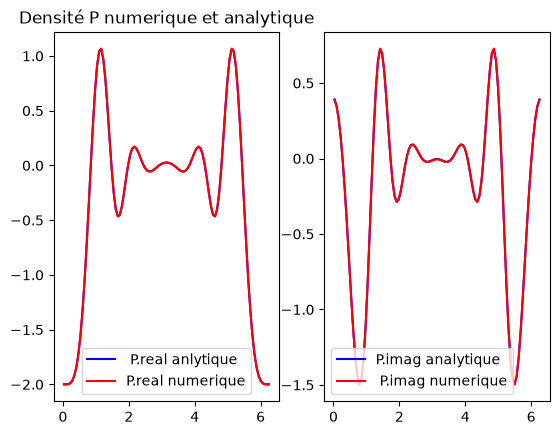

In [ ]:
# On résout le système linéaire

p, info = gmres(A, b, rtol=1e-10)






#on prend les angles pour la sol analytique

#theta = np.linspace(0,2*np.pi, Nbre_elmt,endpoint = False)
theta_milieux = np.arctan2(Milieux[:,1], Milieux[:,0]) % (2*np.pi)


p_analytique = P(a,theta_milieux, k, a, N)

erreur_abs = np.max(np.abs(p - p_analytique))

erreur_rel = (
    np.max(np.abs(p - p_analytique)) 
    / np.max(np.abs(p_analytique))
)

print(f"Erreur absolue : {erreur_abs:.10f}")
print(f"Erreur relative : {erreur_rel:.10f}")

print("Nombre d'éléments :", Nbre_elmt)
print("nq :", nq)
print("k :", k)
print("N_modes :", N)

#On fait les plots

fig, ax = plt.subplots(1, 2)
ax[0].plot(theta_milieux, p_analytique.real,'b', label = " P.real anlytique")
ax[0].plot(theta_milieux, p.real,'r',label = "P.real numerique")
ax[0].legend()
ax[0].set_title('Densité P numerique et analytique')

ax[1].plot(theta_milieux,p_analytique.imag,'b',label = "P.imag analytique ")
ax[1].plot(theta_milieux, p.imag,'r',label = " P.imag numerique") 
ax[1].legend()
ax[1].set_title('')

In [57]:


temps_assemblage = t1 - t0


# On résout le système linéaire
t2 = time.perf_counter()

p_num, info = gmres(A, b, rtol=1e-10)

t3 = time.perf_counter()
temps_gmres = t3 - t2

## On affiche les differents temps pour apres pouvoir faire nos courbes de complexités
print("Nombre d'éléments :", Nbre_elmt)
print("Temps assemblage :", temps_assemblage)
print("Temps GMRES :", temps_gmres)
print("Temps total :", temps_assemblage + temps_gmres)


#theta = np.linspace(0,2*np.pi, Nbre_elmt,endpoint = False)
#theta_milieux = np.arctan2(Milieux[:,1], Milieux[:,0]) % (2*np.pi)

#p_analytique = P(a, theta_milieux, k, a, N)

#erreur_abs = np.max(np.abs(p_num - p_analytique))

#erreur_rel = (
 #   np.max(np.abs(p_num - p_analytique))
  #  / np.max(np.abs(p_analytique))
#)
#print("Nombre de point de Gauss :", nq)
#print("Nombre d'éléments :", Nbre_elmt)
#print("Erreur absolue :", erreur_abs)
#print("Erreur relative :", erreur_rel)




Nombre d'éléments : 100
Temps assemblage : 2.237919064002199
Temps GMRES : 0.10444268299761461
Temps total : 2.3423617469998135


Pente = -2.004517665408246


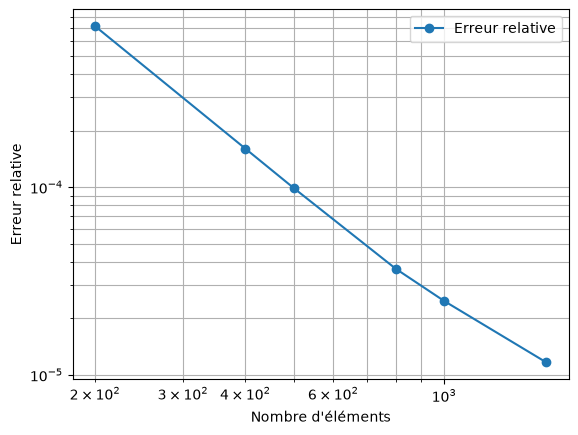

In [62]:
## Courbe de l'erreur en fonction du nombre d'élément en echele log-log


Nbre_elmts = np.array([200, 400, 500, 800, 1000, 1600])

erreurs_rel = np.array([
    7.184539110683591e-4,
    1.6007639787183706e-4,
    9.870215050494419e-5,
    3.672943309864258e-5,
    2.474714776638098e-5,
    1.167523337491887e-5
])

coeff = np.polyfit(
    np.log(Nbre_elmts),
    np.log(erreurs_rel),
    1
)

print("Pente =", coeff[0])

plt.figure()

plt.loglog(Nbre_elmts, erreurs_rel, 'o-', label="Erreur relative")

plt.xlabel("Nombre d'éléments")
plt.ylabel("Erreur relative")
plt.grid(True, which="both")
plt.legend()

plt.show()

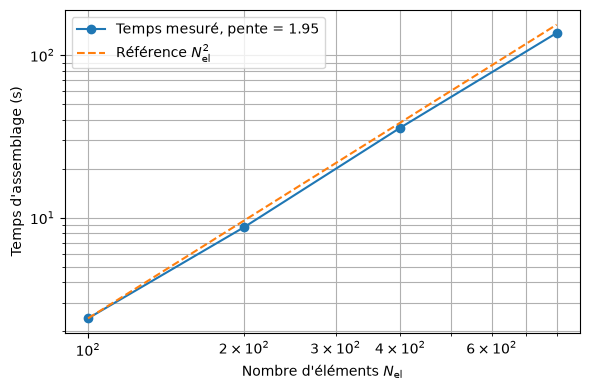

In [63]:



# Courbe de complexité de  Construction de la matrice


N = np.array([100, 200, 400, 800])

T_assemblage = np.array([
    2.4024863970007573,
    8.747622397000669,
    35.77010791000066,
    136.63238659499984
])

# pente expérimentale
pente = np.polyfit(np.log(N), np.log(T_assemblage), 1)[0]

# référence en N^2
reference = T_assemblage[0]*(N/N[0])**2

plt.figure(figsize=(6,4))

plt.loglog(N, T_assemblage, 'o-',
           label=fr"Temps mesuré, pente = {pente:.2f}")

plt.loglog(N, reference, '--',
           label=r"Référence $N_{\mathrm{el}}^2$")

plt.xlabel(r"Nombre d'éléments $N_{\mathrm{el}}$")
plt.ylabel("Temps d'assemblage (s)")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()

plt.savefig("complexite_assemblage.png", dpi=300)
plt.show()


